<a href="https://colab.research.google.com/github/pvgfarias/olist-ecommerce/blob/main/olist_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brazilian E-Commerce (Olist): Deliveries, Reviews and Repeat Customers

Olist connects small and medium Brazilian stores to the large online marketplaces.
This project analyzes a public sample of its data (about 100,000 orders placed by
customers across Brazil between 2016 and 2018) to understand the growth of the business,
where deliveries fell short. We would also like to check whether that affects if customers are likely to order again.

Data: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle)

## Questions

1. How did orders and revenue change month by month?
2. Where are deliveries late, and by how much?
3. Do late deliveries hurt review scores?
4. Do customers come back?

## Key findings

*To be added as each question is answered.*

## Data checks

- 97% of orders (96,478) were delivered. The rest were shipped, canceled, unavailable
  or still processing, which is why 2,965 orders have no delivery date.
  Delivery analysis uses delivered orders only.
- Orders run from September 2016 to October 2018. The first and last months are
  incomplete, so they shouldn't be read as a trend.
- Review scores are always filled in; written comments are optional
  (59% of reviews have no message).

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from scipy import stats
drive.mount('/content/drive')

path = '/content/drive/MyDrive/olist/'
# parse_dates turns the purchase column into real dates, so we can group by month later
orders = pd.read_csv(path + 'olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'])
items = pd.read_csv(path + 'olist_order_items_dataset.csv')
customers = pd.read_csv(path + 'olist_customers_dataset.csv')
reviews = pd.read_csv(path + 'olist_order_reviews_dataset.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Size of each table: items has more rows than orders because one order can have several products
tables = {'orders': orders, 'items': items, 'customers': customers, 'reviews': reviews}

pd.DataFrame({name: {'rows': df.shape[0], 'columns': df.shape[1]}
              for name, df in tables.items()}).T

,rows,columns
orders,99441,8
items,112650,7
customers,99441,5
reviews,99224,7


# Data checks
Checking columns, missing values and the date range before analysis.

In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [4]:
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [5]:
orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [6]:
orders['order_purchase_timestamp'].agg(['min', 'max'])

,order_purchase_timestamp
min,2016-09-04 21:15:19
max,2018-10-17 17:30:18


In [7]:
reviews.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0



- 97% of orders (96,478) were delivered. The rest were shipped, canceled, unavailable
  or still processing, which is why 2,965 orders have no delivery date.
  Delivery analysis uses delivered orders only.
- Orders run from September 2016 to October 2018. The first and last months are
  incomplete, so they shouldn't be read as a trend.
- Review scores are always filled in; written comments are optional
  (59% of reviews have no message).

## 1. Monthly orders and revenue.

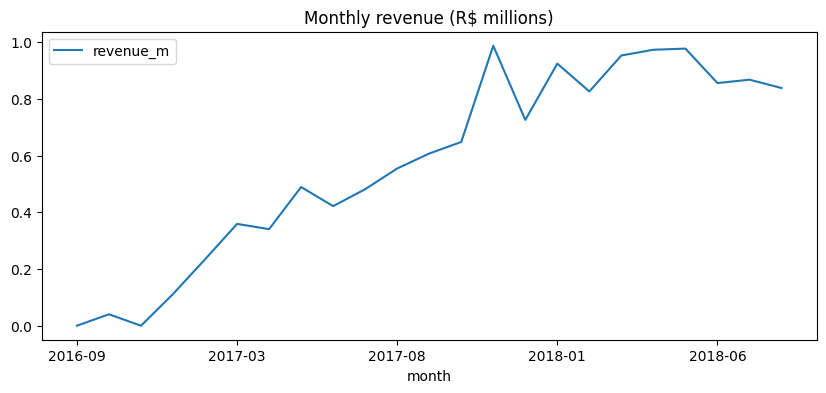

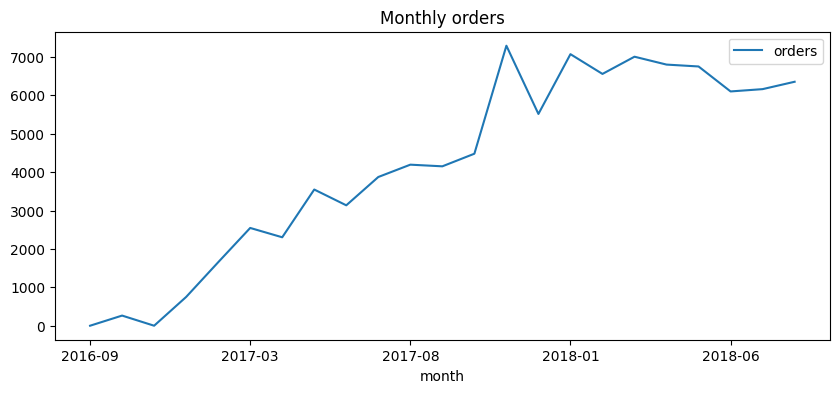

In [8]:
delivered = orders[orders['order_status'] == 'delivered']
df = pd.merge(delivered, items, on='order_id', how='inner')
df['month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
monthly = df.groupby(by='month').agg(
    orders = ('order_id', 'nunique'),
    revenue = ('price', 'sum')
).reset_index()

# showing revenue as millions
monthly['revenue_m'] = monthly['revenue'] / 1_000_000

monthly.plot(x='month', y='revenue_m', title='Monthly revenue (R$ millions)', figsize=(10, 4))
monthly.plot(x='month', y='orders', title='Monthly orders', figsize=(10, 4))
plt.show()

**Findings:** The data starts being recorded in 2016, so the jump from 2016 to 2017 does not tell us much yet. However, we can see a steady growth during 2017. In November 2017, there is a peak of about 7300 orders and revenue of about R$1 million, which is when Black Friday happens. In 2018, the orders stop growing at about 6-7k per month. Since we only considered the delivered cases, the data in 2018's last month is incomplete because some orders were probably still being delivered.

*Note: revenue = product price only, excluding freight (freight_value).*

## 2. Estimated date vs delivery date.

Average delay: 10.6 days
Late orders: 6.8%
   customer_state  orders  pct_late  avg_delay
1              AL     397      21.4        9.5
9              MA     717      17.4       10.5
24             SE     335      15.2       16.2
16             PI     476      13.9       13.3
5              CE    1279      13.8       15.2
4              BA    3256      12.2       12.0
21             RR      41      12.2       36.4
18             RJ   12353      12.1       13.5
13             PA     946      11.2       12.8
7              ES    1995      10.7       11.3


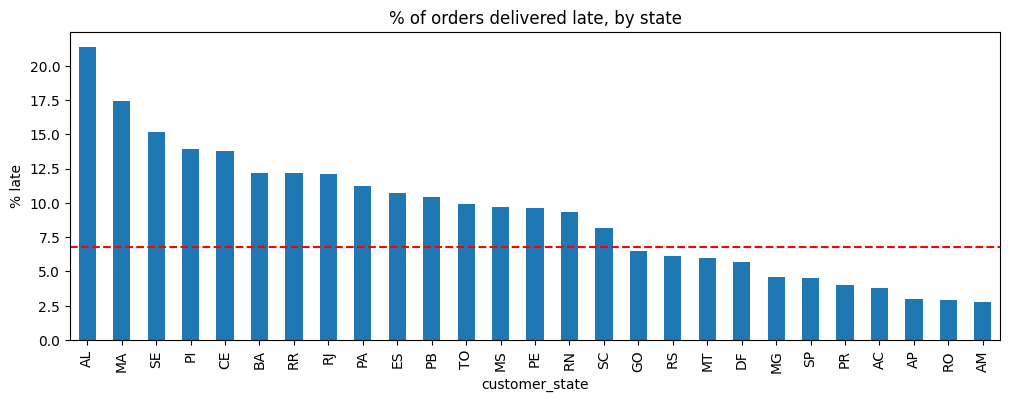

In [17]:
# 1. Remove orders with no delivery date
deliv = orders.dropna(subset=['order_delivered_customer_date']).copy()

# 2. Join with the customer table to get the customer_state
deliv = pd.merge(deliv, customers, on='customer_id', how='left')

# 3. Average delay will be only late orders, delay = delivered - estimated in days (.dt.days)
# Orders delivered on the estimated day count as on time.
deliv['delay_days'] = (deliv['order_delivered_customer_date'] - deliv['order_estimated_delivery_date']).dt.days
deliv['late'] = deliv['delay_days'] > 0
deliv['late_delay'] = deliv['delay_days'].where(deliv['late'])


# 4. Groupby it to calculate mean of the late column and number of orders with agg then plot.
by_state = deliv.groupby('customer_state').agg(
    orders=('order_id', 'nunique'),
    pct_late=('late', 'mean'),
    avg_delay=('late_delay', 'mean')
).reset_index()

by_state['pct_late'] = (by_state['pct_late'] * 100).round(1)
by_state['avg_delay'] = by_state['avg_delay'].round(1)
by_state = by_state.sort_values('pct_late', ascending=False)

by_state.plot(x='customer_state', y='pct_late', kind='bar', title='% of orders delivered late, by state', legend=False, ylabel='% late', figsize=(12, 4))
national_avg = deliv['late'].mean() * 100
print(f'Average delay: {deliv['late_delay'].mean():.1f} days')
print(f'Late orders: {national_avg:.1f}%')
print(by_state.head(10))
plt.axhline(national_avg, color='red', linestyle='--')
plt.show()

**Findings:** Out of all the orders, around 6.8% were late. The states that showed the most late orders were AL (21%) and MA (17%), about 2.5–3× the national average. It's clear from the graph that most of the states with late orders are located in the Northeast region. Some of the states located in the north and southeast had fewer late orders, which may be explained by longer estimated delivery dates for distant states and the location of the Olist sellers and warehouses. In particular RR had very few orders which may explain why it's above other states in the north region. RJ stands out too: it's the 2nd biggest market (12,353 orders) and still 12% late, which affects far more customers than AL. When orders were late, the delay was around 10 days.

## 3. Late orders and reviews.

(97005, 21)
late
False    4.289842
True     2.271139
Name: review_score, dtype: float64
TtestResult(statistic=np.float64(-132.04704262661815), pvalue=np.float64(0.0), df=np.float64(96357.0))


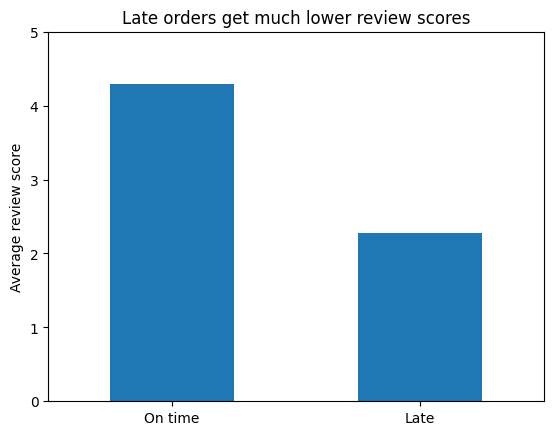

In [41]:
# 1. We need to get the review score of the late orders
# After the merge, the dataframe grows by 529 rows, meaning some orders have more than one review.
orders_reviews = pd.merge(deliv, reviews, on='order_id', how='left')

# 2. Calculate the average review score of late orders and on time orders
scores = orders_reviews.groupby('late')['review_score'].mean()

# 3. Now we must check if our finding is valid, meaning that it's not up to chance that the on time score is higher than the late one.
# Null hypothesis: late and on-time orders have the same average review score
# Significance level: 0.05
late_scores = orders_reviews[orders_reviews['late']]['review_score'].dropna()
ontime_scores = orders_reviews[~orders_reviews['late']]['review_score'].dropna()
result = stats.ttest_ind(late_scores, ontime_scores)
print(orders_reviews.shape)
print(scores)
print(result)

# 4. Late vs on time bar chart.
scores.index = ['On time', 'Late']
scores.plot(kind='bar', title='Late orders get much lower review scores', ylabel='Average review score', xlabel='', rot=0, ylim=(0,5) )
plt.show()

The average review score of on time orders was around 4.3, whereas the late orders showed a drop of 2 points at around 2.3. To check whether this difference is not by chance, we employed a t-test with a significance level of 0.05. The results showed the p-value is lower than 0.001, so the difference is statistically significant. The 2 point drop is also practically significant, which likely reflects customers' frustration with delays. It's important to note this is not an A/B test because lateness wasn't randomly assigned, so this shows an association, not proof that lateness causes the low scores. Other factors (region, seller, product) could also play a part.
